In [1]:
# load data
import pandas as pd

df = pd.read_csv('caffeine_crash_and_anxiety_telemetry.csv')
df

,user_id,age,gender,cyp1a2_metabolizer_type,caffeine_tolerance,baseline_anxiety_score,prior_sleep_hours,daily_hydration_liters,primary_caffeine_source,caffeine_mg,sugar_grams,consumption_duration_min,heart_rate_spike_bpm,jitters_intensity_score,acute_anxiety_score,crash_onset_hours,crash_severity_score,crash_risk_level
0,CAF-00001,27,Female,Fast,High,2.4,7.0,2.29,Brewed Drip Coffee,138,8.7,36,2.0,1.0,1.0,7.5,4.1,Mild Afternoon Fatigue
1,CAF-00002,57,Female,Fast,Low,9.1,7.1,2.41,Energy Drink (Sugar-Free),164,0.0,3,2.4,2.0,5.5,7.5,2.5,Sustained / Negligible Crash
2,CAF-00003,39,Male,Normal,Low,2.9,5.1,2.07,Energy Drink (Full Sugar),179,36.9,10,3.8,4.8,5.5,3.6,7.9,Moderate Crash & Lethargy
3,CAF-00004,34,Female,Fast,Moderate,3.8,5.0,2.34,Pre-Workout Supplement,408,1.6,3,6.8,4.2,7.3,7.5,10.0,Severe Crash & Tachycardia
4,CAF-00005,22,Female,Slow,High,2.0,6.3,1.92,Energy Drink (Full Sugar),170,50.2,11,2.0,2.0,1.1,2.6,10.0,Severe Crash & Tachycardia
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7995,CAF-07996,25,Male,Slow,Moderate,1.8,7.3,1.32,Energy Drink (Sugar-Free),165,0.0,15,8.3,3.8,3.1,4.9,4.1,Mild Afternoon Fatigue
7996,CAF-07997,23,Female,Normal,Moderate,1.0,7.3,0.72,Brewed Drip Coffee,162,5.0,40,2.0,1.2,1.0,6.1,5.0,Mild Afternoon Fatigue
7997,CAF-07998,29,Female,Normal,Low,2.6,5.0,1.06,Brewed Drip Coffee,178,9.8,37,8.3,4.3,4.8,5.4,6.2,Moderate Crash & Lethargy
7998,CAF-07999,52,Female,Fast,Low,1.0,5.7,3.63,Energy Drink (Full Sugar),185,59.8,34,2.0,3.2,3.0,7.1,5.9,Moderate Crash & Lethargy


In [2]:
# EDA
print(f'Cek 5 data teratas \n {df.head()} \n')

print(f'Cek tipe data \n {df.dtypes} \n')

print(f'Cek missing values \n {df.isnull().sum()}')

Cek 5 data teratas 
      user_id  age  gender cyp1a2_metabolizer_type caffeine_tolerance  \
0  CAF-00001   27  Female                    Fast               High   
1  CAF-00002   57  Female                    Fast                Low   
2  CAF-00003   39    Male                  Normal                Low   
3  CAF-00004   34  Female                    Fast           Moderate   
4  CAF-00005   22  Female                    Slow               High   

   baseline_anxiety_score  prior_sleep_hours  daily_hydration_liters  \
0                     2.4                7.0                    2.29   
1                     9.1                7.1                    2.41   
2                     2.9                5.1                    2.07   
3                     3.8                5.0                    2.34   
4                     2.0                6.3                    1.92   

     primary_caffeine_source  caffeine_mg  sugar_grams  \
0         Brewed Drip Coffee          138          8.7 

In [3]:
# outlier
numerical_columns = df.select_dtypes(include='number').columns

outlier_summary = []

for column in numerical_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]

    outlier_summary.append({
        'kolom': column,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'batas_bawah': lower_bound,
        'batas_atas': upper_bound,
        'jumlah_outlier': len(outliers),
        'persen_outlier': round(len(outliers) / len(df) * 100, 2)
    })

outlier_df = pd.DataFrame(outlier_summary)
outlier_df

,kolom,Q1,Q3,IQR,batas_bawah,batas_atas,jumlah_outlier,persen_outlier
0,age,24.00,40.00,16.00,0.000,64.000,38,0.47
1,baseline_anxiety_score,1.80,4.60,2.80,-2.400,8.800,243,3.04
2,prior_sleep_hours,5.50,7.30,1.80,2.800,10.000,0,0.00
3,daily_hydration_liters,1.56,2.65,1.09,-0.075,4.285,21,0.26
4,caffeine_mg,157.00,234.00,77.00,41.500,349.500,283,3.54
5,sugar_grams,0.80,34.60,33.80,-49.900,85.300,0,0.00
6,consumption_duration_min,10.00,45.00,35.00,-42.500,97.500,2,0.03
7,heart_rate_spike_bpm,2.00,6.20,4.20,-4.300,12.500,424,5.30
8,jitters_intensity_score,1.30,4.50,3.20,-3.500,9.300,228,2.85
9,acute_anxiety_score,1.70,5.10,3.40,-3.400,10.200,0,0.00


In [4]:
# handle outlier
numerical_columns = df.select_dtypes(include='number').columns

Q1 = df[numerical_columns].quantile(0.25)
Q3 = df[numerical_columns].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = (
    (df[numerical_columns] < lower_bound) |
    (df[numerical_columns] > upper_bound)
)

outlier_summary = pd.DataFrame({
    'Outlier Count': outlier_mask.sum(),
    'Percentage': outlier_mask.mean() * 100
})

outlier_summary.sort_values(
    by='Outlier Count',
    ascending=False
)

,Outlier Count,Percentage
heart_rate_spike_bpm,424,5.3000
caffeine_mg,283,3.5375
baseline_anxiety_score,243,3.0375
jitters_intensity_score,228,2.8500
age,38,0.4750
daily_hydration_liters,21,0.2625
consumption_duration_min,2,0.0250
prior_sleep_hours,0,0.0000
sugar_grams,0,0.0000
acute_anxiety_score,0,0.0000


In [5]:
# split data
x = df.drop(columns = ['crash_risk_level'])
y = df['crash_risk_level']

from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.2,
    random_state=42
)

In [6]:
# encoding
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

# --- Target & fitur ---
target = "crash_risk_level"

leak_cols = ["crash_severity_score", "crash_onset_hours",
             "heart_rate_spike_bpm", "jitters_intensity_score",
             "acute_anxiety_score"]

X = df.drop(columns=[target] + leak_cols)
y = df[target]

# --- Kelompok kolom ---
ord_cols = ["caffeine_tolerance"]
ohe_cols = ["gender", "cyp1a2_metabolizer_type", "primary_caffeine_source"]
num_cols = [c for c in X.columns if c not in ord_cols + ohe_cols]

# --- Encoding ---
pre = ColumnTransformer([
    ("ord", OrdinalEncoder(categories=[["Low", "Moderate", "High"]]), ord_cols),
    ("ohe", OneHotEncoder(handle_unknown="ignore", drop="first"), ohe_cols),
    ("num", StandardScaler(), num_cols),
])

pipe = Pipeline([
    ("pre", pre),
    ("clf", LogisticRegression(class_weight="balanced", max_iter=1000)),
])

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
pipe.fit(X_tr, y_tr)

# Cek hasil encoding
print(pipe[:-1].get_feature_names_out())

ValueError: could not convert string to float: 'CAF-07915'

In [ ]:
# training model
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score

# --- Target & fitur ---
target = "crash_risk_level"
leak_cols = ["crash_severity_score", "crash_onset_hours",
             "heart_rate_spike_bpm", "jitters_intensity_score",
             "acute_anxiety_score"]

X = df.drop(columns=[target] + leak_cols)
y = df[target]

ord_cols = ["caffeine_tolerance"]
ohe_cols = ["gender", "cyp1a2_metabolizer_type", "primary_caffeine_source"]
num_cols = [c for c in X.columns if c not in ord_cols + ohe_cols]

def make_pre(scale=True, drop_first=False):
    return ColumnTransformer([
        ("ord", OrdinalEncoder(categories=[["Low", "Moderate", "High"]]), ord_cols),
        ("ohe", OneHotEncoder(handle_unknown="ignore",
                              drop="first" if drop_first else None), ohe_cols),
        ("num", StandardScaler() if scale else "passthrough", num_cols),
    ])

models = {
    "Logistic Regression": Pipeline([
        ("pre", make_pre(scale=True, drop_first=True)),
        ("clf", LogisticRegression(class_weight="balanced", max_iter=2000)),
    ]),
    "Random Forest": Pipeline([
        ("pre", make_pre(scale=False)),
        ("clf", RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                       random_state=42, n_jobs=-1)),
    ]),
    "Hist Gradient Boosting": Pipeline([
        ("pre", make_pre(scale=False)),
        ("clf", HistGradientBoostingClassifier(class_weight="balanced", random_state=42)),
    ]),
}

# --- Split ---
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Distribusi kelas:\n", y.value_counts(normalize=True).round(3), "\n")

# --- Training & evaluasi ---
cv = StratifiedKFold(5, shuffle=True, random_state=42)
results = []

for name, pipe in models.items():
    pipe.fit(X_tr, y_tr)
    pred = pipe.predict(X_te)
    cv_f1 = cross_val_score(pipe, X, y, cv=cv, scoring="f1_macro", n_jobs=-1)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_te, pred),
        "F1 macro (test)": f1_score(y_te, pred, average="macro"),
        "F1 macro (CV)": cv_f1.mean(),
        "CV std": cv_f1.std(),
    })
    print(f"===== {name} =====")
    print(classification_report(y_te, pred))

print(pd.DataFrame(results).round(4).to_string(index=False))

# --- Confusion matrix model terbaik (berdasarkan F1 CV) ---
best = max(results, key=lambda r: r["F1 macro (CV)"])["Model"]
print(f"\nModel terbaik: {best}")
labels = sorted(y.unique())
print(pd.DataFrame(confusion_matrix(y_te, models[best].predict(X_te), labels=labels),
                   index=labels, columns=labels))

# --- Fitur terpenting (kalau Random Forest) ---
rf = models["Random Forest"]
imp = pd.Series(rf[-1].feature_importances_,
                index=rf[:-1].get_feature_names_out()).sort_values(ascending=False)
print("\nTop 10 fitur (Random Forest):\n", imp.head(10))

Distribusi kelas:
 crash_risk_level
Moderate Crash & Lethargy       0.303
Mild Afternoon Fatigue          0.297
Severe Crash & Tachycardia      0.270
Sustained / Negligible Crash    0.130
Name: proportion, dtype: float64 

===== Logistic Regression =====
                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.78      0.67      0.73       476
   Moderate Crash & Lethargy       0.72      0.76      0.74       485
  Severe Crash & Tachycardia       0.88      0.86      0.87       432
Sustained / Negligible Crash       0.71      0.89      0.79       207

                    accuracy                           0.78      1600
                   macro avg       0.77      0.80      0.78      1600
                weighted avg       0.78      0.78      0.78      1600

===== Random Forest =====
                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.74      0.71      0.72       476
   Moderate Cra

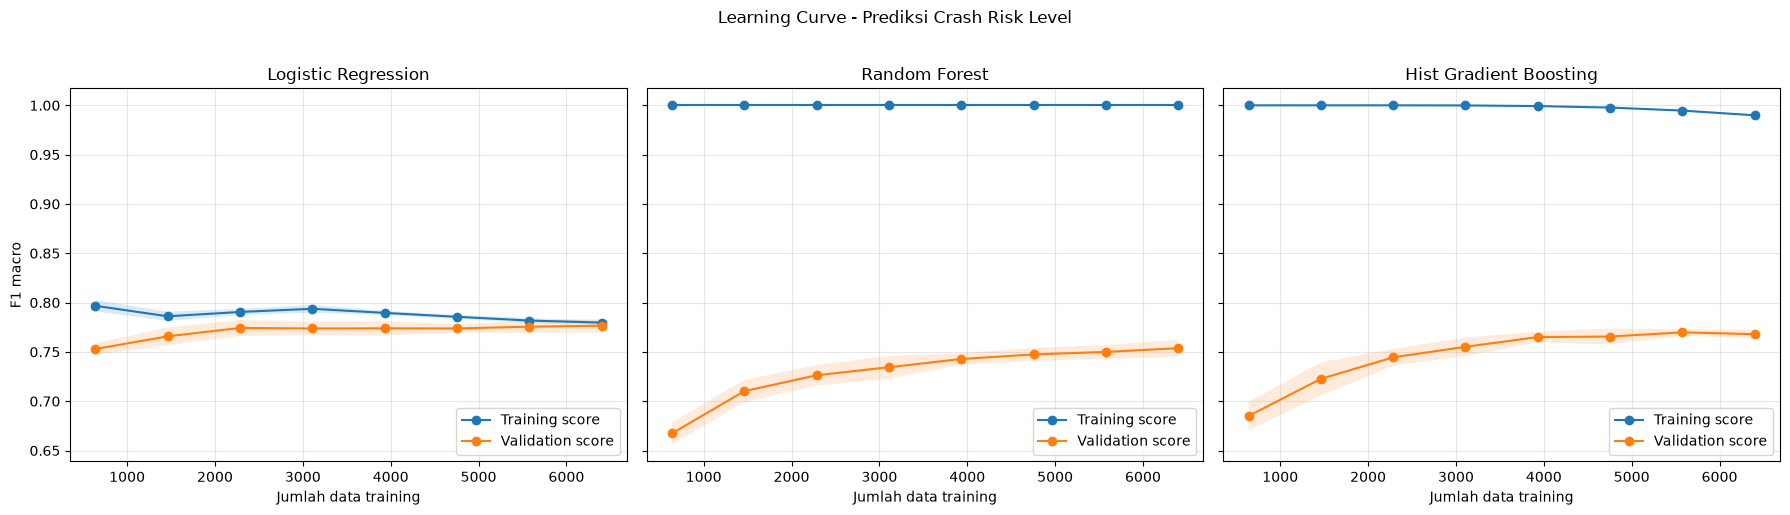

In [ ]:
# learning curve
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve, StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for ax, (name, pipe) in zip(axes, models.items()):
    train_sizes, train_scores, val_scores = learning_curve(
        pipe, X, y,
        train_sizes=np.linspace(0.1, 1.0, 8),
        cv=cv,
        scoring="f1_macro",
        n_jobs=-1,
    )

    train_mean, train_std = train_scores.mean(axis=1), train_scores.std(axis=1)
    val_mean, val_std = val_scores.mean(axis=1), val_scores.std(axis=1)

    ax.plot(train_sizes, train_mean, "o-", label="Training score")
    ax.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15)
    ax.plot(train_sizes, val_mean, "o-", label="Validation score")
    ax.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.15)
    ax.set_title(name)
    ax.set_xlabel("Jumlah data training")
    ax.grid(alpha=0.3)
    ax.legend(loc="lower right")

axes[0].set_ylabel("F1 macro")
plt.suptitle("Learning Curve - Prediksi Crash Risk Level", y=1.02)
plt.tight_layout()
plt.show()